## Project Overview

This notebook documents the data inspection, cleaning, and validation process for the E-Commerce Sales Analytics dataset obtained from Kaggle.

The objective is to assess data quality, investigate potential inconsistencies and unusual observations, and prepare the dataset for subsequent business analysis.

The broader project aims to analyze revenue performance across product categories, regions, and time, and explore potential relationships between discounts, delivery duration, and customer ratings. Since the dataset does not contain cost or expense information, profitability cannot be directly assessed.

The dataset contains 5,000 synthetic retail transactions and is being used for learning and portfolio development.

### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Load data

In [2]:
data = pd.read_csv("C:/Coursera/ecommerce-business-analytics/data/raw/ecommerce_sales_analytics_5000.csv")

### Initial data inspection

In [3]:
data.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [4]:
#Size of the data
data.shape

(5000, 12)

In [5]:
#Columns in the data 
data.columns

Index(['order_id', 'order_date', 'customer_id', 'product_category', 'region',
       'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days',
       'customer_rating', 'revenue'],
      dtype='object')

### Data Quality Assessment and Validation

1. Missing values
2. Data type of the columns
3. Duplicate values
4. Invalid/Impossible values
5. Inconsistent Categorical values
6. Cross columns consistency

In [6]:
#Missing values
data.isna().sum()

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

In [7]:
#Data type of the columns
data.dtypes

order_id              int64
order_date           object
customer_id           int64
product_category     object
region               object
quantity              int64
unit_price          float64
discount            float64
payment_method       object
delivery_days         int64
customer_rating     float64
revenue             float64
dtype: object

In [8]:
data['order_date'] = pd.to_datetime(data['order_date'])

In [9]:
data.dtypes

order_id                     int64
order_date          datetime64[ns]
customer_id                  int64
product_category            object
region                      object
quantity                     int64
unit_price                 float64
discount                   float64
payment_method              object
delivery_days                int64
customer_rating            float64
revenue                    float64
dtype: object

In [10]:
#Date Range verification
print("Earliest order:", data['order_date'].min())
print("Latest order:", data['order_date'].max())
print("Unique order dates:", data['order_date'].nunique())

Earliest order: 2022-01-01 00:00:00
Latest order: 2035-09-09 00:00:00
Unique order dates: 5000


In [11]:
#Duplicate rows
data.duplicated().sum()

np.int64(0)

In [12]:
#Duplicate rows corresponding to the ID columns
duplicates = data[data.duplicated(subset=['order_id'], keep=False)]
print(duplicates)

Empty DataFrame
Columns: [order_id, order_date, customer_id, product_category, region, quantity, unit_price, discount, payment_method, delivery_days, customer_rating, revenue]
Index: []


In [13]:
#Invalid/Impossible values
data.describe()

,order_id,order_date,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,2028-11-04 12:00:00,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
min,10001.000000,2022-01-01 00:00:00,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,11250.750000,2025-06-03 18:00:00,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,12500.500000,2028-11-04 12:00:00,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,13750.250000,2032-04-07 06:00:00,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,15000.000000,2035-09-09 00:00:00,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000
std,1443.520003,NaN,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219


In [14]:
#Inconsistant categorical value 
data['product_category'].value_counts()

product_category
Electronics    1777
Clothing       1531
Home            969
Beauty          723
Name: count, dtype: int64

In [15]:
data['payment_method'].value_counts()

payment_method
Card      2270
COD       1774
Wallet     956
Name: count, dtype: int64

In [16]:
#Cross columns consistency
data['calculated_revenue'] = (data['unit_price']*data['quantity']) *(1- data['discount'])
data['is_consistent'] = np.isclose(
    data['revenue'], data['calculated_revenue'], atol=0.01
)

print(data['is_consistent'].value_counts())

is_consistent
True    5000
Name: count, dtype: int64


In [17]:
data.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue,calculated_revenue,is_consistent
0,10001,2022-01-01,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20,1883.1960,True
1,10002,2022-01-02,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10,304.1038,True
2,10003,2022-01-03,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35,644.3496,True
3,10004,2022-01-04,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90,2569.9030,True
4,10005,2022-01-05,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56,468.5645,True


### Outlier investigation

Histograms and boxplots were used to examine numerical distributions and identify potentially unusual observations. The highest-revenue records were investigated using quantity, unit price, and discount. Observations were retained provisionally because no material inconsistency was identified in the revenue calculation check. This does not establish that every unusual observation is necessarily valid.

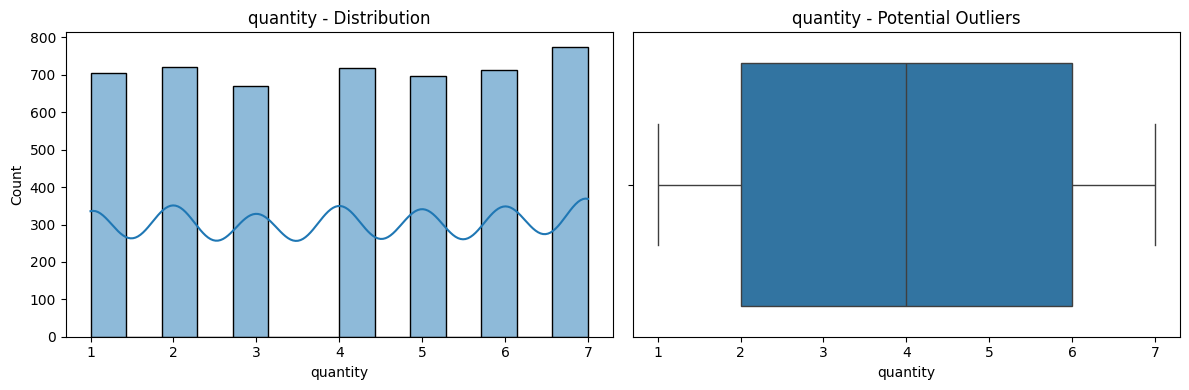

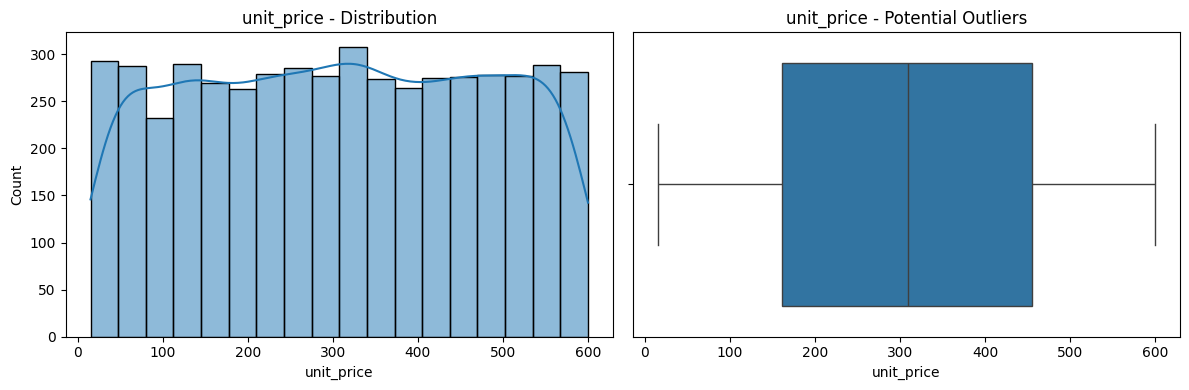

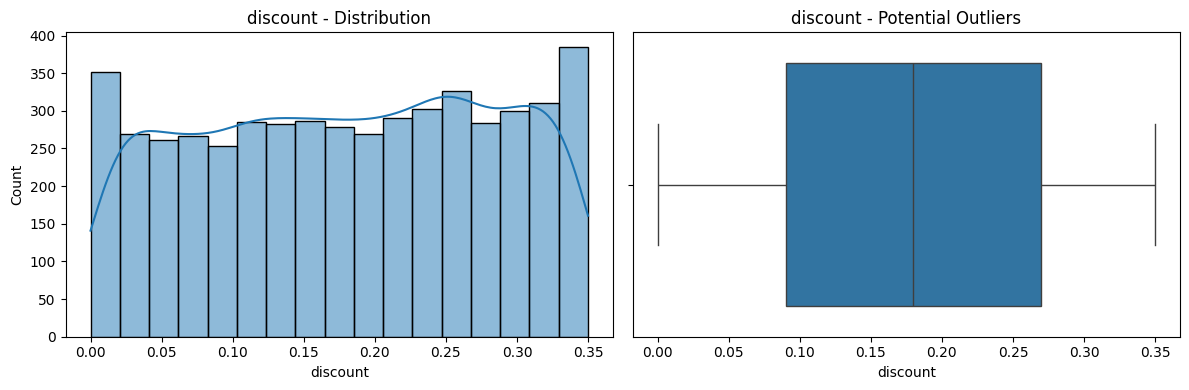

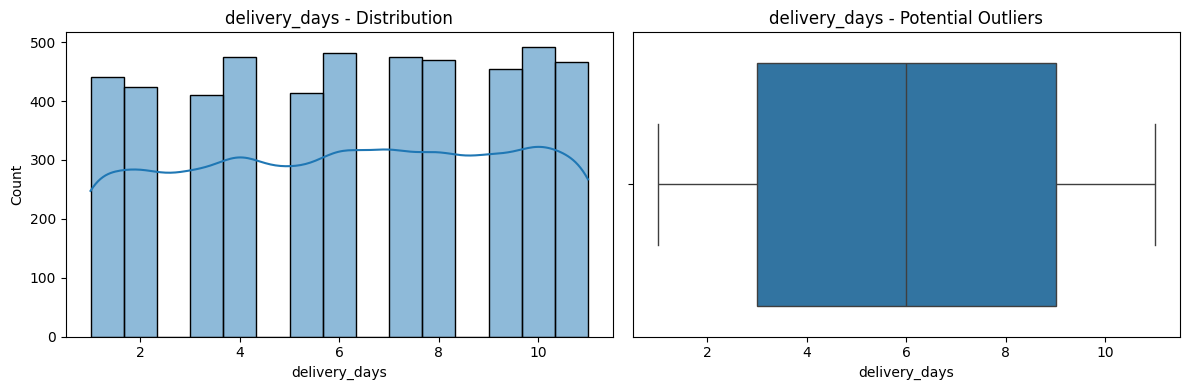

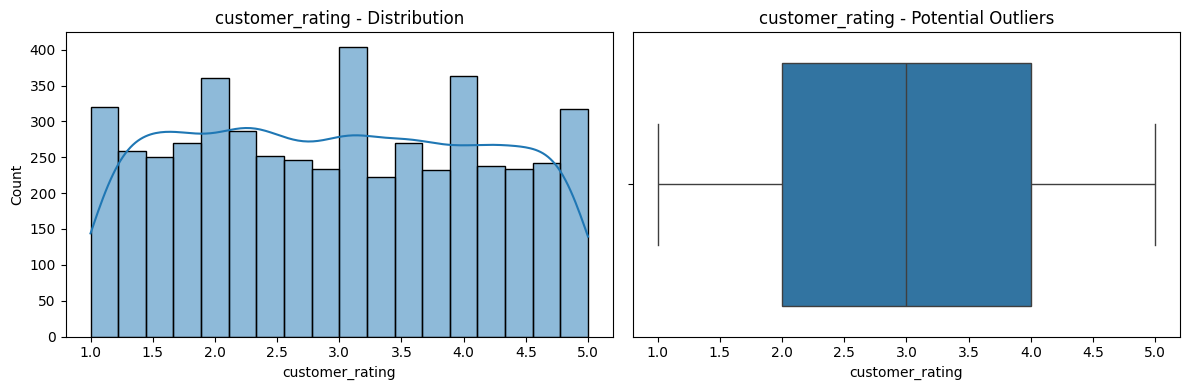

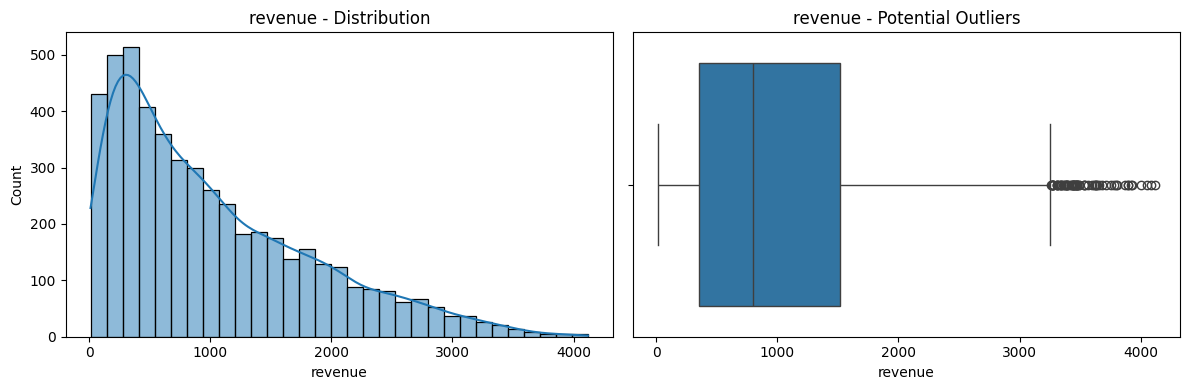

In [18]:
cols_to_plot = [
    'quantity',
    'unit_price',
    'discount',
    'delivery_days',
    'customer_rating',
    'revenue'
]

for col in cols_to_plot:
    if col not in data.columns:
        continue

    values = data[col].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(
        x=values,
        kde=True,
        ax=axes[0]
    )
    axes[0].set_title(f'{col} - Distribution')

    sns.boxplot(
        x=values,
        ax=axes[1]
    )
    axes[1].set_title(f'{col} - Potential Outliers')

    plt.tight_layout()
    plt.show()

In [19]:
#Investigating the largest orders
data.nlargest(10, 'revenue')[
    [
        'order_id',
        'product_category',
        'quantity',
        'unit_price',
        'discount',
        'revenue'
    ]
]

,order_id,product_category,quantity,unit_price,discount,revenue
809,10810,Electronics,7,594.42,0.01,4119.33
4883,14884,Electronics,7,583.31,0.00,4083.17
2214,12215,Electronics,7,591.15,0.02,4055.29
3101,13102,Beauty,7,596.12,0.04,4005.93
3686,13687,Clothing,7,578.59,0.03,3928.63
157,10158,Electronics,7,571.07,0.02,3917.54
3349,13350,Electronics,7,574.15,0.03,3898.48
321,10322,Electronics,7,585.43,0.05,3893.11
661,10662,Clothing,7,581.67,0.05,3868.11
4305,14306,Beauty,7,555.09,0.02,3807.92


In [20]:
expected_revenue = (
    data['quantity']
    * data['unit_price']
    * (1 - data['discount'])
)

difference = (
    data['revenue'] - expected_revenue
).abs()

print("Maximum absolute difference:", difference.max())
print("Records exceeding tolerance:", (difference > 0.02).sum())

Maximum absolute difference: 0.005000000000109139
Records exceeding tolerance: 0


In [21]:
high_revenue = data.nlargest(10, 'revenue')

print("Top 10 revenue records:")
display(
    high_revenue[
        ['quantity', 'unit_price', 'discount', 'revenue']
    ].describe()
)

print("Overall dataset:")
display(
    data[
        ['quantity', 'unit_price', 'discount', 'revenue']
    ].describe()
)

Top 10 revenue records:


,quantity,unit_price,discount,revenue
count,10.0,10.000000,10.000000,10.000000
mean,7.0,581.100000,0.027000,3957.751000
std,0.0,12.291401,0.016364,102.368656
min,7.0,555.090000,0.000000,3807.920000
25%,7.0,575.260000,0.020000,3894.452500
50%,7.0,582.490000,0.025000,3923.085000
75%,7.0,589.720000,0.037500,4042.950000
max,7.0,596.120000,0.050000,4119.330000


Overall dataset:


,quantity,unit_price,discount,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000
mean,4.044800,308.418774,0.179984,1021.955148
std,2.020398,169.259369,0.101404,825.584219
min,1.000000,15.150000,0.000000,11.210000
25%,2.000000,161.895000,0.090000,354.527500
50%,4.000000,309.890000,0.180000,796.650000
75%,6.000000,455.557500,0.270000,1515.690000
max,7.000000,599.960000,0.350000,4119.330000


In [22]:
#Business rule check
checks = {
    'quantity_positive': data['quantity'] > 0,
    'unit_price_positive': data['unit_price'] > 0,
    'discount_in_range': data['discount'].between(0, 1),
    'rating_in_range': data['customer_rating'].between(1, 5),
    'delivery_days_nonnegative': data['delivery_days'] >= 0
}

for name, condition in checks.items():
    print(f"{name}: {condition.all()}")

quantity_positive: True
unit_price_positive: True
discount_in_range: True
rating_in_range: True
delivery_days_nonnegative: True


### Remove Temporary Validation Columns

In [23]:
data = data.drop(
    columns=['calculated_revenue', 'is_consistent']
)

print(data.shape)
print(data.columns.tolist())

(5000, 12)
['order_id', 'order_date', 'customer_id', 'product_category', 'region', 'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days', 'customer_rating', 'revenue']


### Cleaned Data

In [25]:
data.to_csv("cleaned_ecommerce_data.csv", index=False)
cleaned_data = pd.read_csv(
    'cleaned_ecommerce_data.csv'
)

print("Shape:", cleaned_data.shape)
print("Missing values:", cleaned_data.isna().sum().sum())
print("Columns:", cleaned_data.columns.tolist())

Shape: (5000, 12)
Missing values: 0
Columns: ['order_id', 'order_date', 'customer_id', 'product_category', 'region', 'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days', 'customer_rating', 'revenue']


### Summary of Data Quality Assessment

1. **Dataset structure:** The working dataset contains 5,000 rows and 12 columns.
2. **Missing values:** No missing values were detected during the initial assessment.
3. **Data types:** The `order_date` column was converted to datetime format for date-based analysis.
4. **Duplicates:** No exact duplicate rows or repeated `order_id` values were detected.
5. **Categorical columns:** Product categories and payment methods were inspected using frequency counts. No standardization changes should be claimed unless inconsistencies were identified and addressed.
6. **Revenue consistency:** Recorded revenue was compared against the assumed formula `quantity × unit_price × (1 − discount)`. The maximum absolute difference was approximately 0.005, and no records exceeded the selected tolerance of 0.02. The formula remains an assumption unless confirmed by the dataset source.
7. **Outlier investigation:** Revenue showed a right-skewed distribution. High-revenue observations were examined and retained provisionally because no material inconsistency was identified by the revenue validation check.
8. **Numeric validation:** Checks were performed for positive quantities and unit prices, discounts between 0 and 1, ratings between 1 and 5, and non-negative delivery durations. The results should be documented according to the actual outputs.
9. **Final preparation:** Temporary validation columns were removed. The final dataset should be exported and checked to ensure that it retains the intended 12 columns.

The prepared dataset will be used for subsequent SQL-based business analysis, with the assumptions and limitations documented above taken into account.